<a href="https://colab.research.google.com/github/Rayonnocap/HW_repo_2026/blob/main/hw_1_poletaev.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Домашнее задание. Тема: Обнаружение сетевых вторжений (IDS) на датасете CIC-IDS2017

**Программные инструменты анализа данных в ИБ**

**Студент:** Полетаев Владислав Ильич

**Группа:** РИ-431001

Содержание:
1. Постановка задачи
2. Выбор и обоснование метрик качества
3. Разведочный анализ данных
4. Выводы и план дальнейшей работы (примерно что буду делать)


## 1. Задачи

Вообще тему такую выбрал, потому что пишу диплом "разработка LLM-агента для определения критичности инцидентов ИБ". Ну и отталкивался от найденного датасета.

### 1.1 Бизнес

В корпоративной сети постоянно возникают тысячи сетевых соединений. IDS - системы обнаружения вторжений (по типу Suricata и других) хорошо ловят известные атаки, но пропускают видоизменённые и новые, а также создают большой поток ложных срабатываний, из-за которого аналитики SOC постоянно сталкиваются с ложными срабатываниями и тратят много времени на обработку таких инцидентов ИБ

**Цель:** построить ML-детектор, который по статистическим характеристикам сетевого трафика (длительность, число и размер пакетов, флаги TCP и тд.) определяет, является ли трафик вредоносным. Детектор должен дополнять сигнатурную IDS и помогать аналитикам приоритизировать алерты.

### 1.2 ML

- **Тип задачи:** бинарная классификация, один пример это один сетевой поток
- **Целевая переменная:** BENIGN (0) против ATTACK (1)
- **Признаки:** около 78 числовых признаков, рассчитанных инструментом CICFlowMeter
- **Расширение проекта:** можно сделать расширенную классификацию типа атаки (DoS, DDoS, PortScan, Brute Force, Web Attack, Botnet и др.).

### 1.3 Набор данных

Используем датасет **CIC-IDS2017** в котором есть: размеченные сетевые потоки за пять дней работы тестовой сети с нормальным трафиком и атаками.
Ссылка на источник: https://www.unb.ca/cic/datasets/ids-2017.html

Используется архив **MachineLearningCSV.zip** 8 CSV-файлов по дням и временным окнам

В датасете около 2,8 млн размеченных потоков, представлено множество (десятки тысяч если верить интернетам) примеров основных семейств атак, есть большой объём нормального трафика

**Ограничения датасета**
- трафик сгенерирован в лабораторной среде, а не снят в реальной сети, то есть может сильно отличаться от примеров, где злоумышленники специально пытаются замаскировать атаку под что-то легитимное.
- атаки запускались готовыми инструментами в заранее определённое время (Как я понял по типу OpenBAS Agent)
- Вообще уже после выполнения нашел информацию, что датасет с ошибками и устарел, есть более большая версия, которую не посчитал нужным использовать в работе из-за размера


## 2. Выбор и обоснование метрик

Сначала определим, что будет считаться ошибкой:

|  | "Атака" | "Норма" |
|---|---|---|
| **Это атака** | TP: атака обнаружена | **FN: атака пропущена** |
| **Это норма** | **FP: ложное срабатывание** | TN: всё верно |


| Метрика | Что показывает | Почему подходит для этой задачи |
|---|---|---|
| **Recall (полнота) по классу «атака»** | доля настоящих атак, которые мы нашли | Пропущенная атака (FN) означает необнаруженную компрометацию, поэтому берем эту метрику как основную |
| **Precision и FPR** | доля настоящих атак среди тревог; доля нормальных потоков, ложно названных атакой | На миллионах потоков даже малый FPR даёт тысячи ложных алертов. Аналитики перестают на них реагировать (alert fatigue). |
| **F1 и macro-F1** | баланс precision и recall; macro-F1 усредняет по классам | Нужны для мультиклассовой постановки: редкие атаки (Heartbleed, SQL Injection) иначе потеряются на фоне крупных классов. |
| **PR-AUC** | качество при всех возможных порогах | Корректнее ROC-AUC при дисбалансе классов и не зависит от выбранного порога. |
| **Recall при фиксированном FPR** (например, FPR ≤ 0,1 %) | сколько атак найдём при допустимом уровне ложных тревог | Отражает реальный режим эксплуатации IDS: допустимый FPR задаёт бизнес, а не модель. |

Нормального трафика в датасете намного больше, чем атак. Поэтому "точность" в работе используется только как справочная метрика

## 3. Разведочный анализ данных (EDA)

### 3.0 Подготовка

**Перед запуском:**
Я подключил к коллабу свой гугл диск и надеюсь все файлы загрузятся должным образом, на тесте все исправно работало.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Оформление графиков
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

SEED = 42                                    # чтобы случайные выборки повторялись
DATA_DIR = Path("/content/drive/MyDrive/")   # ПУТЬ ДО ФАЙЛОВ ДАТАСЕТА

SAMPLE_FRAC = 1.0

### 3.1 Загрузка данных

В общем, датасет большой - около 2,8 млн строк, поэтому при загрузке сразу уменьшим занимаемую память, для этого числовые столбцы приводим к float32. Дополнительно запоминаем, из какого файла пришла каждая строка, в имени файла есть день недели и время

Файлы читаем в кодировке latin-1 потому что в одном из файлов есть символ (как оказалось), который не читается как UTF-8, и с кодировкой по умолчанию вылезала ошибка

In [ ]:
def load_cic_ids2017(data_dir: Path, frac: float = 1.0) -> pd.DataFrame:
    files = sorted(data_dir.glob("*.csv"))
    parts = []
    for f in files:
        part = pd.read_csv(f, encoding="latin-1", low_memory=False)
        part.columns = part.columns.str.strip()          # у части названий есть пробелы
        if frac < 1.0:
            part = part.sample(frac=frac, random_state=SEED)
        num_cols = part.select_dtypes(include="number").columns
        part[num_cols] = part[num_cols].astype("float32")  # экономим память
        part["source_file"] = (
            f.name.replace(".pcap_ISCX.csv", "").replace(".csv", "")
        )
        print(f"{f.name:<70} {part.shape[0]:>9,} строк")
        parts.append(part)

    return pd.concat(parts, ignore_index=True)


df_raw = load_cic_ids2017(DATA_DIR, SAMPLE_FRAC)
print(f"\nДЛя проверки. Всего: {df_raw.shape[0]:,} строк, {df_raw.shape[1]} столбцов")

Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv                         225,745 строк
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv                     286,467 строк
Friday-WorkingHours-Morning.pcap_ISCX.csv                                191,033 строк
Monday-WorkingHours.pcap_ISCX.csv                                        529,918 строк
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv              288,602 строк
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv                   170,366 строк
Tuesday-WorkingHours.pcap_ISCX.csv                                       445,909 строк
Wednesday-workingHours.pcap_ISCX.csv                                     692,703 строк

Итого: 2,830,743 строк, 80 столбцов


### 3.2 Базовые характеристики набора данных

In [ ]:
print("Размер таблицы:", df_raw.shape)
print(f"Память: {df_raw.memory_usage(deep=True).sum() / 1024**2:,.0f} МБ")
df_raw.head()

Размер таблицы: (2830743, 80)
Память: 1,198 МБ


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Min Packet Length,Max Packet Length,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Header Length.1,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,source_file
0,"54,865.000",3.000,2.000,0.000,12.000,0.000,6.000,6.000,6.000,0.000,0.000,0.000,0.000,0.000,"4,000,000.000","666,666.688",3.000,0.000,3.000,3.000,3.000,3.000,0.000,3.000,3.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,40.000,0.000,"666,666.688",0.000,6.000,6.000,6.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,9.000,6.000,0.000,40.000,0.000,0.000,0.000,0.000,0.000,0.000,2.000,12.000,0.000,0.000,33.000,-1.000,1.000,20.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,BENIGN,Friday-WorkingHours-Afternoon-DDos
1,"55,054.000",109.000,1.000,1.000,6.000,6.000,6.000,6.000,6.000,0.000,6.000,6.000,6.000,0.000,"110,091.742","18,348.623",109.000,0.000,109.000,109.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,20.000,20.000,"9,174.312","9,174.312",6.000,6.000,6.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,1.000,0.000,0.000,1.000,9.000,6.000,6.000,20.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,6.000,1.000,6.000,29.000,256.000,0.000,20.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,BENIGN,Friday-WorkingHours-Afternoon-DDos
2,"55,055.000",52.000,1.000,1.000,6.000,6.000,6.000,6.000,6.000,0.000,6.000,6.000,6.000,0.000,"230,769.234","38,461.539",52.000,0.000,52.000,52.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,20.000,20.000,"19,230.770","19,230.770",6.000,6.000,6.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,1.000,0.000,0.000,1.000,9.000,6.000,6.000,20.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,6.000,1.000,6.000,29.000,256.000,0.000,20.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,BENIGN,Friday-WorkingHours-Afternoon-DDos
3,"46,236.000",34.000,1.000,1.000,6.000,6.000,6.000,6.000,6.000,0.000,6.000,6.000,6.000,0.000,"352,941.188","58,823.531",34.000,0.000,34.000,34.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,20.000,20.000,"29,411.766","29,411.766",6.000,6.000,6.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,1.000,0.000,0.000,1.000,9.000,6.000,6.000,20.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,6.000,1.000,6.000,31.000,329.000,0.000,20.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,BENIGN,Friday-WorkingHours-Afternoon-DDos
4,"54,863.000",3.000,2.000,0.000,12.000,0.000,6.000,6.000,6.000,0.000,0.000,0.000,0.000,0.000,"4,000,000.000","666,666.688",3.000,0.000,3.000,3.000,3.000,3.000,0.000,3.000,3.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,40.000,0.000,"666,666.688",0.000,6.000,6.000,6.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,9.000,6.000,0.000,40.000,0.000,0.000,0.000,0.000,0.000,0.000,2.000,12.000,0.000,0.000,32.000,-1.0

In [ ]:
# Типы данных
print(df_raw.dtypes.value_counts())
print("\nНечисловые столбцы:", list(df_raw.select_dtypes(exclude="number").columns))

float32    78
object      2
Name: count, dtype: int64

Нечисловые столбцы: ['Label', 'source_file']


In [ ]:
# Описание для числовых признаков
# inf временно заменяем на NaN, иначе статистики считаются некорректно
num_cols_raw = df_raw.select_dtypes(include="number").columns
df_raw[num_cols_raw].replace([np.inf, -np.inf], np.nan).describe().T

,count,mean,std,min,25%,50%,75%,max
Destination Port,"2,830,743.000","8,071.479","18,369.467",0.000,53.000,80.000,443.000,"65,535.000"
Flow Duration,"2,830,743.000","14,785,659.000","33,918,600.000",-13.000,155.000,"31,316.000","3,204,828.500","120,000,000.000"
Total Fwd Packets,"2,830,743.000",9.361,749.607,1.000,2.000,2.000,5.000,"219,759.000"
Total Backward Packets,"2,830,743.000",10.394,997.315,0.000,1.000,2.000,4.000,"291,922.000"
Total Length of Fwd Packets,"2,830,743.000",549.302,"9,982.318",0.000,12.000,62.000,187.000,"12,900,000.000"
...,...,...,...,...,...,...,...,...
Active Min,"2,830,743.000","58,295.809","574,502.062",0.000,0.000,0.000,0.000,"110,000,000.000"
Idle Mean,"2,830,743.000","8,316,037.500","23,455,520.000",0.000,0.000,0.000,0.000,"120,000,000.000"
Idle Std,"2,830,743.000","503,843.906","4,576,147.500",0.000,0.000,0.000,0.000,"76,900,000.000"
Idle Max,"2,830,743.000","8,695,756.000","24,463,476.000",0.000,0.000,0.000,0.000,"120,000,000.000"


### 3.3 Качество данных: пропуски, бесконечности, дубликаты, странные значения

Проверяем всё, что может сломать обучение модели.

In [ ]:
num_cols_raw = df_raw.select_dtypes(include="number").columns

# 1. Пропуски
na = df_raw.isna().sum()
print("Пропуски (по столбцам, только где они есть):")
print(na[na > 0].to_string() if (na > 0).any() else "пропусков нет")

# 2. Бесконечные значения
inf_cnt = np.isinf(df_raw[num_cols_raw]).sum()
print("\nБесконечные значения (inf):")
print(inf_cnt[inf_cnt > 0].to_string() if (inf_cnt > 0).any() else "inf нет")

# 3. Отрицательные значения (для длительностей и счётчиков это подозрительно)
neg_cnt = (df_raw[num_cols_raw] < 0).sum()
print("\nСтолбцы с отрицательными значениями:")
print(neg_cnt[neg_cnt > 0].sort_values(ascending=False).to_string() if (neg_cnt > 0).any() else "нет")

# 4. Дублирующиеся по названию столбцы (pandas добавляет к ним суффикс .1)
dup_named = [c for c in df_raw.columns if c.endswith(".1")]
print("\nСтолбцы-дубликаты по названию:", dup_named if dup_named else "нет")

# 5. Константные столбцы (одно и то же значение во всех строках)
nun = df_raw[num_cols_raw].nunique()
const_cols = list(nun[nun == 1].index)
print("\nКонстантные столбцы:", const_cols if const_cols else "нет")

Пропуски (по столбцам, только где они есть):
Flow Bytes/s    1358

Бесконечные значения (inf):
Flow Bytes/s      1509
Flow Packets/s    2867

Столбцы с отрицательными значениями:
Init_Win_bytes_backward    1441552
Init_Win_bytes_forward     1001189
Flow IAT Min                  2891
Flow Packets/s                 115
Flow Duration                  115
Flow IAT Mean                  115
Flow IAT Max                   115
Flow Bytes/s                    85
Fwd Header Length               35
Fwd Header Length.1             35
min_seg_size_forward            35
Bwd Header Length               22
Fwd IAT Min                     17

Столбцы-дубликаты по названию: ['Fwd Header Length.1']

Константные столбцы: ['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']


Комментарий к результату:
1. Пропуски и inf
   - Flow Bytes/s: 1358 NaN и 1509 inf
   - Flow Packets/s: 2867 inf
   Причина: оба признака — это отношения (байты / длительность, пакеты /
   длительность), а в знаменателе стоит Flow Duration.
   У части flow длительность равна 0 (одно-пакетные или мгновенно завершившиеся сессии), из-за чего получаем деление на ноль. а при последующей замене или потере — NaN.
   Доля таких строк мала 0.1% от общего объёма, поэтому все в целом неплохо.

2. Отрицательные значения в признаках, которые по смыслу не могут быть отрицательными. Здесь важно разделить два случая:

   - Init_Win_bytes_backward (1 441 552) и Init_Win_bytes_forward
     (1 001 189) — это НЕ ошибка расчёта, а специальное значение -1,
     означающее «TCP-окно не было инициализировано» (например, для flow, где не наблюдалось TCP-рукопожатия: UDP-трафик сканы, обрезанные захваты).  Строки удалять
     нельзя (это ~половина датасета), нужно трактовать -1 как отдельную
     категорию или как NaN для моделей, чувствительных к знаку.

   - Остальные отрицательные значения занимают очень малый процент, поэтому их можно не учитывать как погрешность.

3. Константные столбцы:
   Bwd PSH Flags, Bwd URG Flags, Fwd/Bwd Avg Bytes/Bulk, Fwd/Bwd Avg
   Packets/Bulk, Fwd/Bwd Avg Bulk Rate.
   Все значения одинаковы, значит нулевая дисперсия и нулевая информативность
   Для обучения моделей их нужно убрать

4. Дубликат столбца:
   'Fwd Header Length.1' — полный дубликат 'Fwd Header Length', возникший при слиянии CSV (типичный артефакт pandas при concat).
   Надо будет удалить один из столбцов.

In [ ]:
# Очистка: делаем копию, чтобы сырые данные остались для сравнения
df = df_raw.copy()

# Единая запись названий меток: убираем пробелы и странные символы
df["Label"] = (
    df["Label"].astype(str)
    .str.replace(r"[^\x20-\x7E]+", "-", regex=True)
    .str.strip()
)

# inf заменяем на NaN, а потом удаляем строки с NaN
n_before = len(df)
num_cols = df.select_dtypes(include="number").columns
df[num_cols] = df[num_cols].replace([np.inf, -np.inf], np.nan)
df = df.dropna()
print(f"Удалено строк с NaN/inf: {n_before - len(df):,} ({(n_before - len(df)) / n_before:.3%})")

# Удаляем столбцы-дубликаты и константные столбцы
to_drop = dup_named + const_cols
df = df.drop(columns=to_drop)
print("Удалены столбцы:", to_drop)

# Бинарная метка: 0 = BENIGN, 1 = ATTACK
df["is_attack"] = (df["Label"] != "BENIGN").astype("int8")

print(f"\nПосле очистки: {df.shape[0]:,} строк, {df.shape[1]} столбцов")

Удалено строк с NaN/inf: 2,867 (0.101%)
Удалены столбцы: ['Fwd Header Length.1', 'Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']

После очистки: 2,827,876 строк, 72 столбцов


In [ ]:
# Полные дубликаты строк (по признакам; источник файла не учитываем).
# На полном датасете эта ячейка может выполняться минуту-две.
feature_cols = [c for c in df.columns if c not in ("source_file", "is_attack")]
n_dup = df.duplicated(subset=feature_cols).sum()
print(f"Полных дубликатов строк: {n_dup:,} ({n_dup / len(df):.2%})")

# Дубликаты по классам: какие метки чаще всего повторяются?
dup_mask = df.duplicated(subset=feature_cols, keep=False)
dup_by_class = dup_mask.groupby(df["Label"]).mean().sort_values(ascending=False)
dup_by_class.to_frame("доля строк-дубликатов")

Полных дубликатов строк: 329,896 (11.67%)


,доля строк-дубликатов
Label,
PortScan,0.639
SSH-Patator,0.479
FTP-Patator,0.309
DoS Hulk,0.255
BENIGN,0.116
DoS slowloris,0.091
DoS Slowhttptest,0.059
Web Attack - Brute Force,0.041
Bot,0.007


Комментарий к результату:
Доля дупликатов в большинстве параметров минимальная, кроме PortScan SSH-Patator
FTP-Patator
DoS Hulk
BENIGN
DoS slowloris
Есть проблема, если одна и та же строка окажется в обеих выборках, и модель будет угадывать то, что уже видела, по этому надо удалять дубликаты до разбиения, пока что не придумал как именно лучше это сделать

### 3.4 Баланс классов

Самый важный график для выбора метрики.

In [ ]:
class_counts = df["Label"].value_counts()
class_table = pd.DataFrame({
    "Количество": class_counts,
    "Доля, %": (class_counts / len(df) * 100).round(4),
})
class_table

,Количество,"Доля, %"
Label,,
BENIGN,2271320,80.319
DoS Hulk,230124,8.138
PortScan,158804,5.616
DDoS,128025,4.527
DoS GoldenEye,10293,0.364
FTP-Patator,7935,0.281
SSH-Patator,5897,0.208
DoS slowloris,5796,0.205
DoS Slowhttptest,5499,0.195


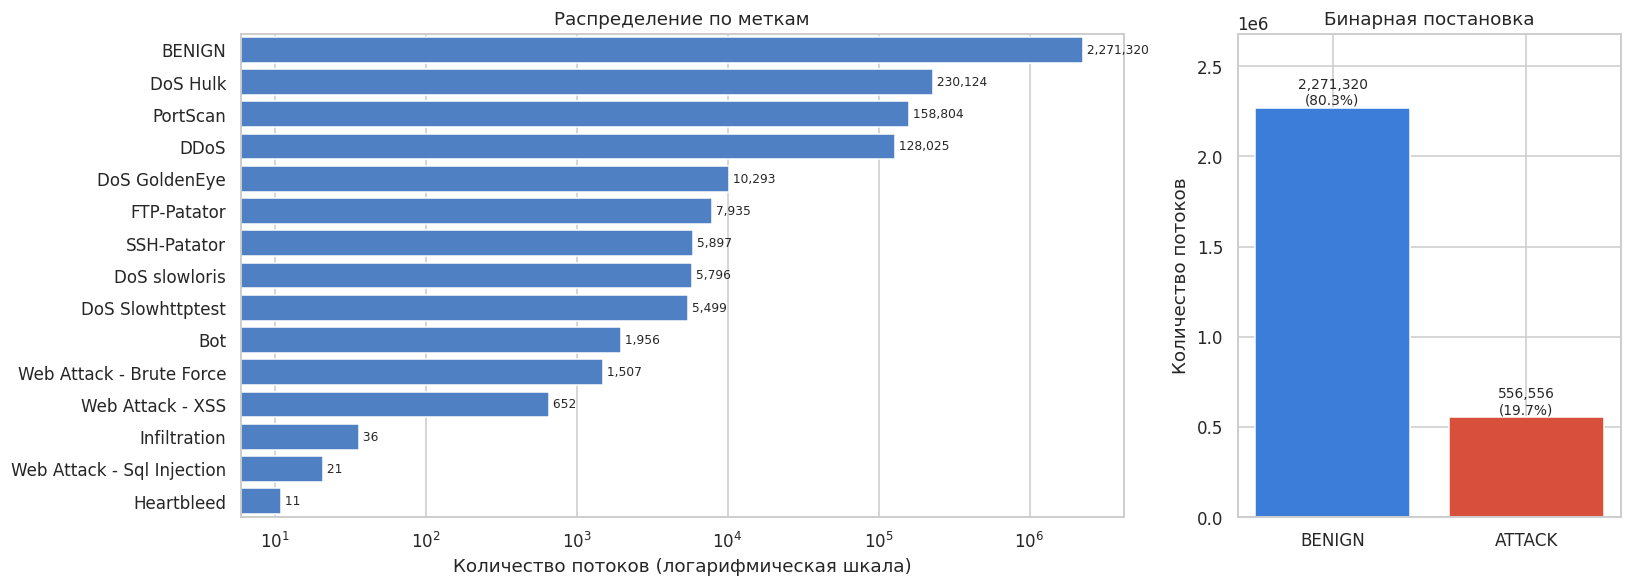

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [2.3, 1]})

# Слева все классы в логарифмической шкале
sns.barplot(x=class_counts.values, y=class_counts.index, ax=axes[0], color="#3b7dd8")
axes[0].set_xscale("log")
axes[0].set_xlabel("Количество потоков (логарифмическая шкала)")
axes[0].set_ylabel("")
axes[0].set_title("Распределение по меткам")
for i, v in enumerate(class_counts.values):
    axes[0].text(v, i, f" {v:,}", va="center", fontsize=8)

# Справа - бинарная постановка
bin_counts = df["is_attack"].map({0: "BENIGN", 1: "ATTACK"}).value_counts()
axes[1].bar(bin_counts.index, bin_counts.values,
            color=["#3b7dd8" if k == "BENIGN" else "#d8503b" for k in bin_counts.index])
axes[1].set_title("Бинарная постановка")
axes[1].set_ylabel("Количество потоков")
axes[1].set_ylim(0, bin_counts.max() * 1.18)   # запас сверху для подписей
for i, v in enumerate(bin_counts.values):
    axes[1].text(i, v, f"{v:,}\n({v / len(df):.1%})", ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()

In [ ]:
# Что будет если модель будет все принимать за норму, пример:
baseline_accuracy = (df["is_attack"] == 0).mean()
print(f"Accuracy модели «всегда норма»: {baseline_accuracy:.2%}")
print("Recall по атакам этой модели:   0.00%  (не найдено ни одной атаки)")

# Самые редкие классы
print("\nСамые редкие классы:")
print(class_counts.tail(5).to_string())

Accuracy модели «всегда норма»: 80.32%
Recall по атакам этой модели:   0.00%  (не найдено ни одной атаки)

Самые редкие классы:
Label
Web Attack - Brute Force      1507
Web Attack - XSS               652
Infiltration                    36
Web Attack - Sql Injection      21
Heartbleed                      11


ДОПИСАТЬ!
Комментарий на гите.



### 3.5 Откуда взялись атаки: распределение по файлам (дням)

Атаки в датасете запускались в определённые часы. Проверим, как классы распределены по файлам.

Label,BENIGN,Bot,DDoS,DoS GoldenEye,DoS Hulk,DoS Slowhttptest,DoS slowloris,FTP-Patator,Heartbleed,Infiltration,PortScan,SSH-Patator,Web Attack - Brute Force,Web Attack - Sql Injection,Web Attack - XSS
source_file,,,,,,,,,,,,,,,
Friday-WorkingHours-Afternoon-DDos,97686,0,128025,0,0,0,0,0,0,0,0,0,0,0,0
Friday-WorkingHours-Afternoon-PortScan,127292,0,0,0,0,0,0,0,0,0,158804,0,0,0,0
Friday-WorkingHours-Morning,188955,1956,0,0,0,0,0,0,0,0,0,0,0,0,0
Monday-WorkingHours,529481,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Thursday-WorkingHours-Afternoon-Infilteration,288359,0,0,0,0,0,0,0,0,36,0,0,0,0,0
Thursday-WorkingHours-Morning-WebAttacks,168051,0,0,0,0,0,0,0,0,0,0,0,1507,21,652
Tuesday-WorkingHours,431813,0,0,0,0,0,0,7935,0,0,0,5897,0,0,0
Wednesday-workingHours,439683,0,0,10293,230124,5499,5796,0,11,0,0,0,0,0,0


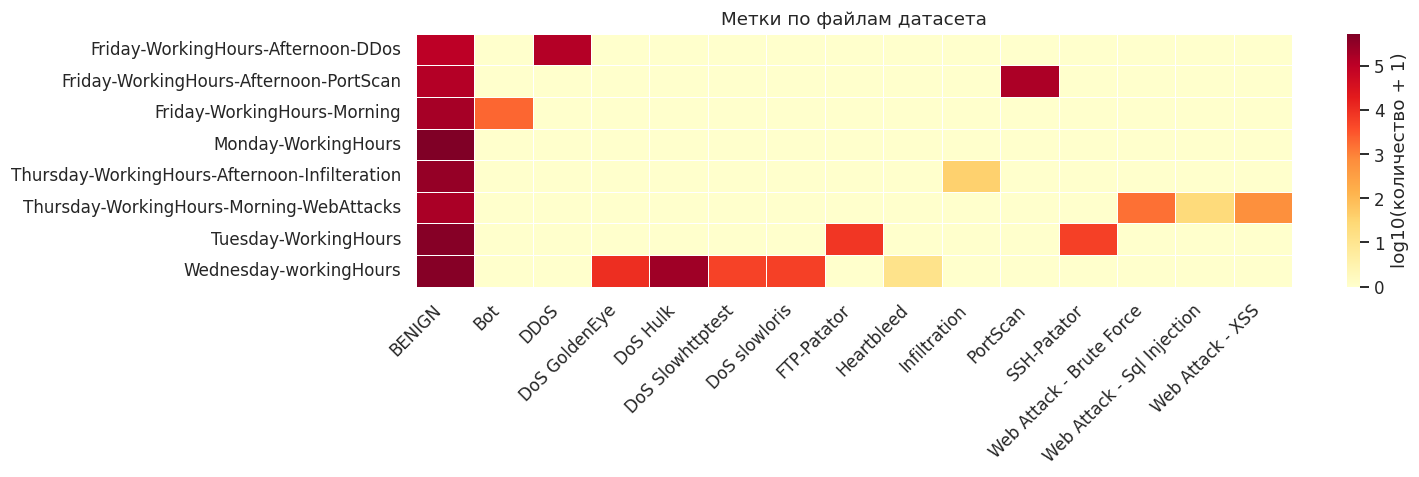

In [ ]:
ct = pd.crosstab(df["source_file"], df["Label"])
display(ct)

# Тепловая карта в логарифмической шкале (иначе мелкие значения не видно, тут спросил нейросеть)
plt.figure(figsize=(14, 4.5))
sns.heatmap(np.log10(ct + 1), cmap="YlOrRd", linewidths=0.4,
            cbar_kws={"label": "log10(количество + 1)"})
plt.title("Метки по файлам датасета")
plt.xlabel("")
plt.ylabel("")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


Комментарий на гите.

### 3.6 Распределения признаков: норма против атак

Признаков много, поэтому сначала смотрим на несколько ключевых. Для наглядности используем выборку: не более 5 000 строк каждого класса.

In [ ]:
# Выборка для графиков: не более N строк каждого класса
N_PER_CLASS = 5000
sample = pd.concat(
    [g.sample(min(len(g), N_PER_CLASS), random_state=SEED) for _, g in df.groupby("Label")],
    ignore_index=True,
)
print(f"Размер выборки для графиков: {len(sample):,} строк")

KEY_FEATURES = [
    "Flow Duration", "Total Fwd Packets", "Total Backward Packets",
    "Flow Bytes/s", "Flow Packets/s", "Fwd Packet Length Mean", "SYN Flag Count",
]
KEY_FEATURES = [c for c in KEY_FEATURES if c in df.columns]
print("Признаки:", KEY_FEATURES)

Размер выборки для графиков: 49,183 строк
Признаки: ['Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Flow Bytes/s', 'Flow Packets/s', 'Fwd Packet Length Mean', 'SYN Flag Count']


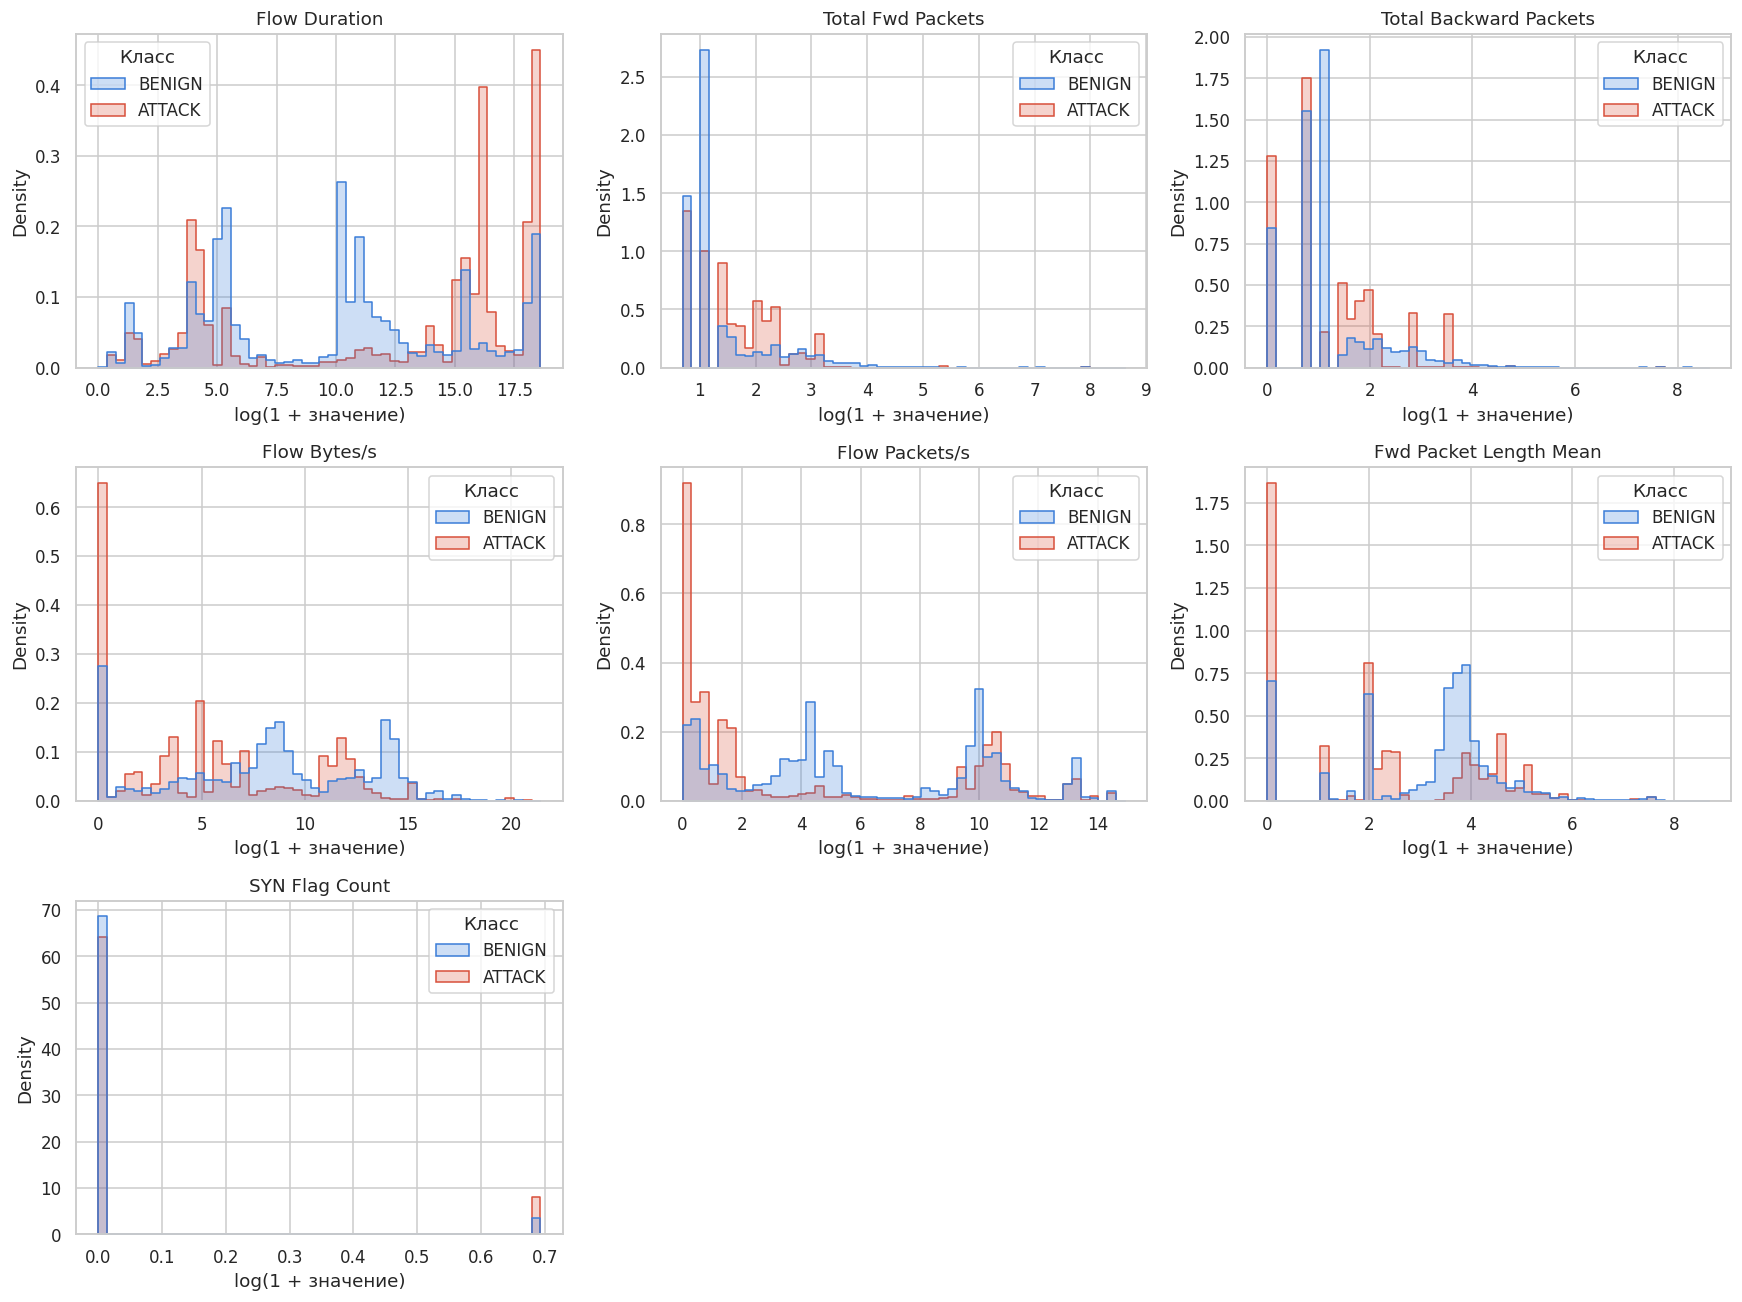

In [ ]:
# Распределения у нормального трафика и у атак.
# используем log(1 + x) как и в некоторых случаях, чтобы можно было нормально увидеть значения от 0 до миллиона и т.д
n = len(KEY_FEATURES)
ncols = 3
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4 * nrows))
axes = np.array(axes).ravel()

for ax, feat in zip(axes, KEY_FEATURES):
    plot_df = pd.DataFrame({
        "x": np.log1p(sample[feat].clip(lower=0)),
        "Класс": sample["is_attack"].map({0: "BENIGN", 1: "ATTACK"}),
    })
    sns.histplot(data=plot_df, x="x", hue="Класс", bins=50, stat="density",
                 common_norm=False, element="step", ax=ax,
                 palette={"BENIGN": "#3b7dd8", "ATTACK": "#d8503b"})
    ax.set_title(feat)
    ax.set_xlabel("log(1 + значение)")

for ax in axes[n:]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

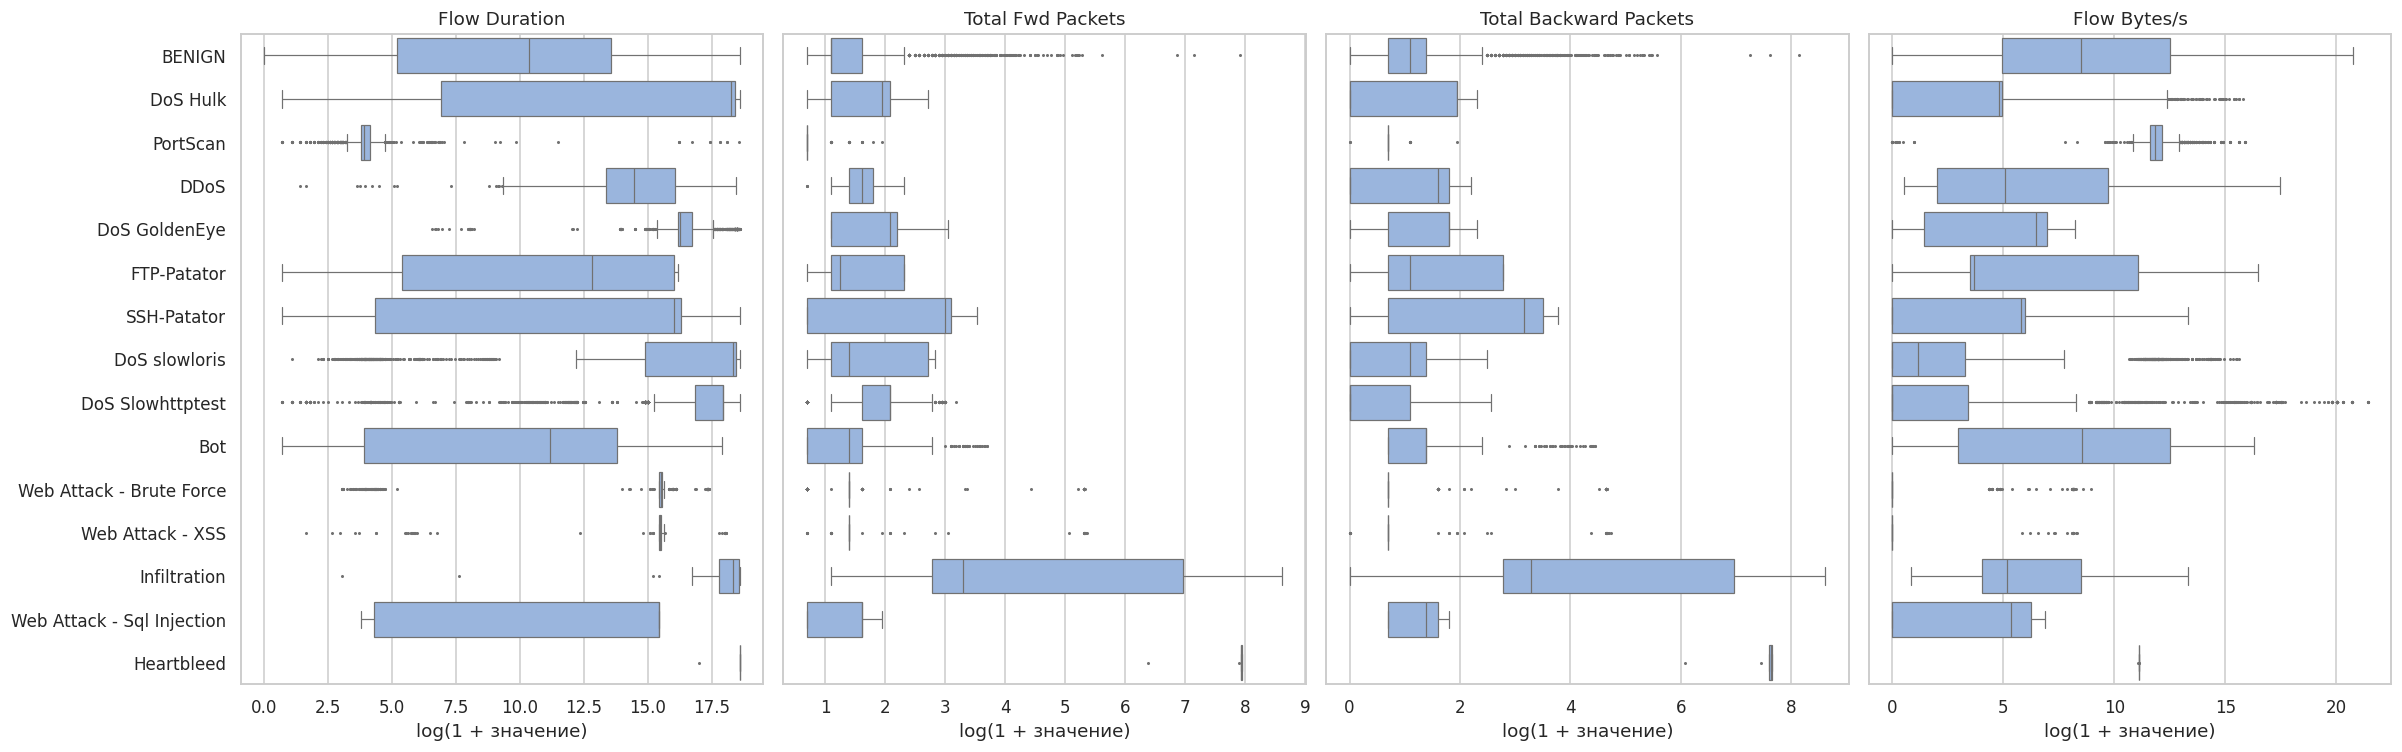

In [ ]:
# Те же признаки, но по каждому типу атаки отдельно
order = class_counts.index.tolist()
n_show = min(4, len(KEY_FEATURES))
fig, axes = plt.subplots(1, n_show, figsize=(5.5 * n_show, 7), sharey=True)
axes = np.atleast_1d(axes)

for ax, feat in zip(axes, KEY_FEATURES[:n_show]):
    plot_df = pd.DataFrame({
        "x": np.log1p(sample[feat].clip(lower=0)),
        "Label": sample["Label"],
    })
    sns.boxplot(data=plot_df, x="x", y="Label", order=order, ax=ax,
                fliersize=1, linewidth=0.8, color="#8fb3e8")
    ax.set_title(feat)
    ax.set_xlabel("log(1 + значение)")
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

**ДОПИСАТЬ!!!: комментарий к распределениям.**


### 3.7 Корреляции признаков

Много признаков CICFlowMeter считаются из одних и тех же величин, поэтому часть из них почти дублирует друг друга.

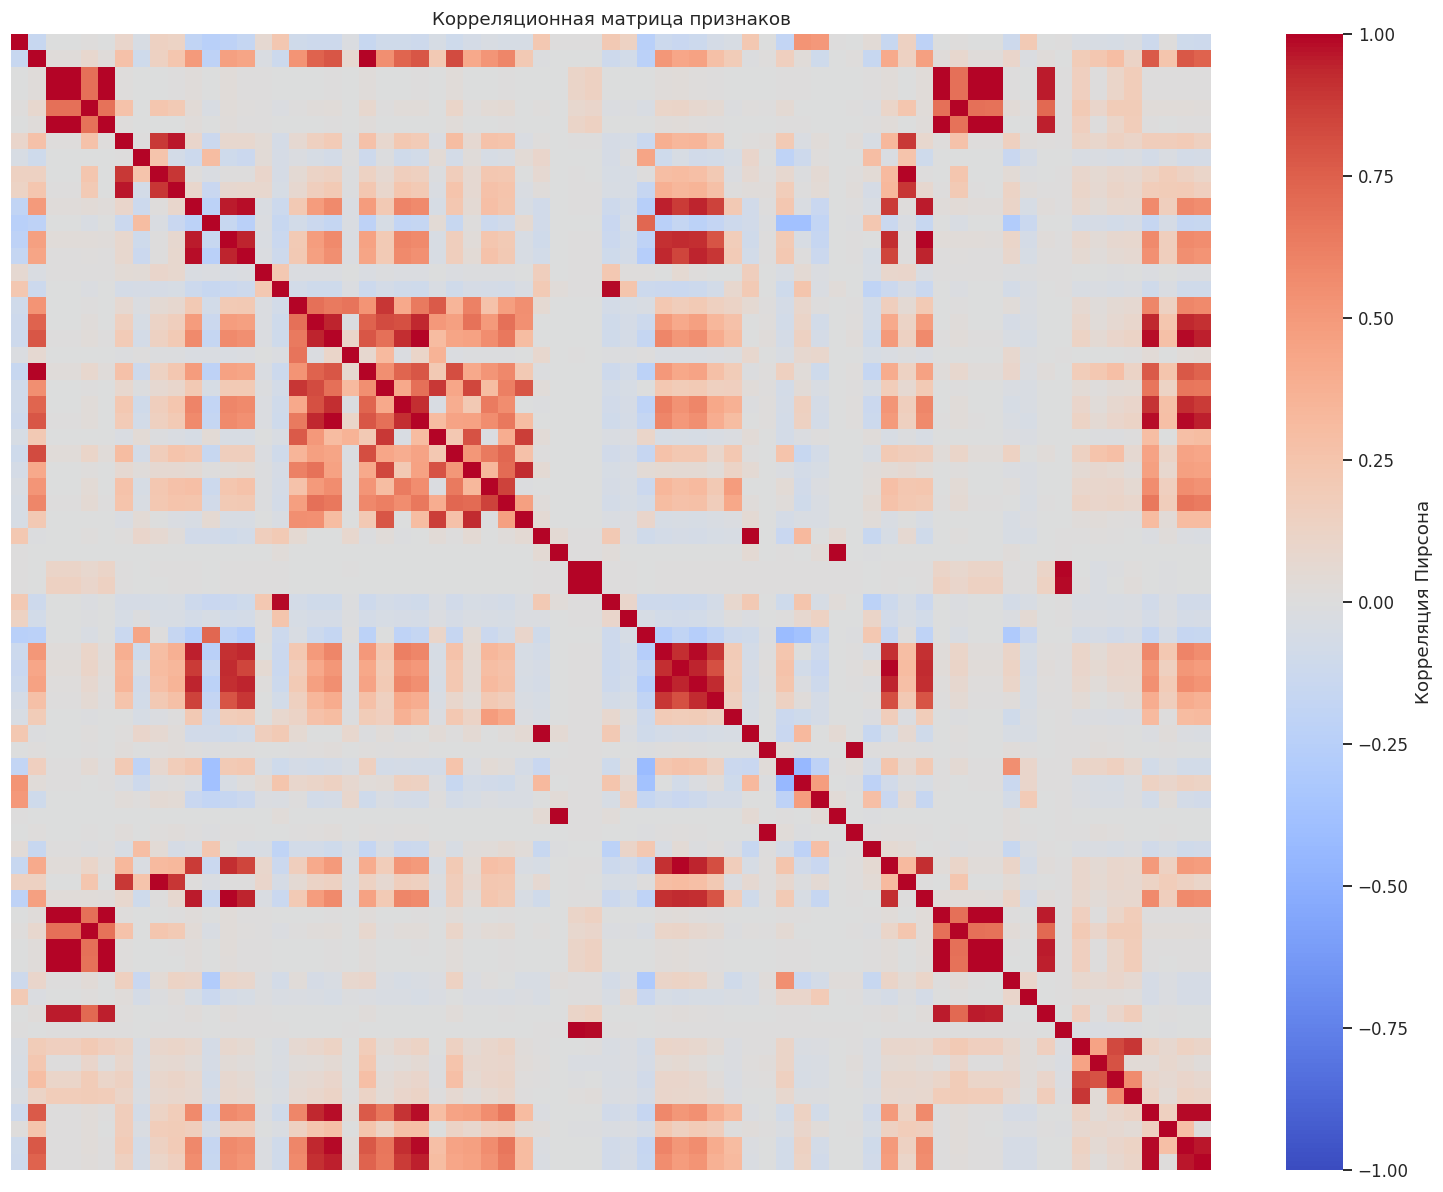

In [ ]:
feat_cols = [c for c in df.select_dtypes(include="number").columns if c != "is_attack"]
corr_sample = df[feat_cols].sample(min(200_000, len(df)), random_state=SEED)
corr = corr_sample.corr()

plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            xticklabels=False, yticklabels=False,
            cbar_kws={"label": "Корреляция Пирсона"})
plt.title("Корреляционная матрица признаков")
plt.tight_layout()
plt.show()

In [ ]:
# Пары признаков с очень высокой корреляцией
THRESH = 0.95
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pairs = (
    upper.stack().rename("corr").reset_index()
    .rename(columns={"level_0": "Признак 1", "level_1": "Признак 2"})
)
high = pairs[pairs["corr"].abs() >= THRESH].sort_values("corr", key=abs, ascending=False)
print(f"Пар признаков с |корреляцией| >= {THRESH}: {len(high)} из {len(pairs):,}")
high.head(15)

Пар признаков с |корреляцией| >= 0.95: 47 из 2,346


,Признак 1,Признак 2,corr
185,Total Fwd Packets,Subflow Fwd Packets,1.000
315,Total Length of Fwd Packets,Subflow Fwd Bytes,1.000
252,Total Backward Packets,Subflow Bwd Packets,1.000
1658,Fwd URG Flags,CWE Flag Count,1.000
1616,Fwd PSH Flags,SYN Flag Count,1.000
789,Bwd Packet Length Mean,Avg Bwd Segment Size,1.000
558,Fwd Packet Length Mean,Avg Fwd Segment Size,1.000
2025,RST Flag Count,ECE Flag Count,1.000
380,Total Length of Bwd Packets,Subflow Bwd Bytes,1.000
187,Total Fwd Packets,Subflow Bwd Packets,1.000


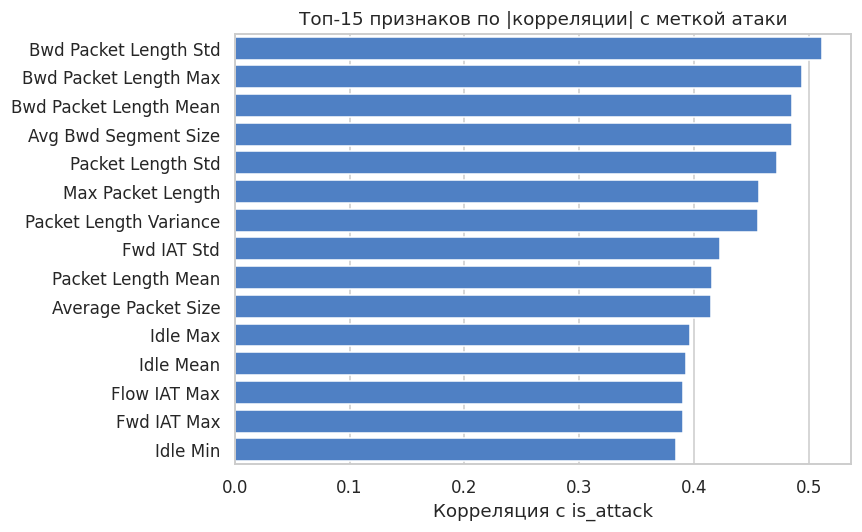

In [ ]:
# Примерно оценим на сколько полезно. Корреляция каждого признака с бинарной меткой
corr_target = corr_sample.corrwith(df.loc[corr_sample.index, "is_attack"]).dropna()
top = corr_target.reindex(corr_target.abs().sort_values(ascending=False).index).head(15)

plt.figure(figsize=(8, 5))
sns.barplot(x=top.values, y=top.index, color="#3b7dd8")
plt.title("Топ-15 признаков по |корреляции| с меткой атаки")
plt.xlabel("Корреляция с is_attack")
plt.ylabel("")
plt.tight_layout()
plt.show()

Комментарий на гите.

## 4. Выводы и план дальнейшей работы

### 4.1 Главные выводы по данным

Напишу выводы в readme.md в гитхабе

### 4.2 План предобработки и моделирования

- **Очистка:** надо удалить строки с NaN/inf, константные и дублирующиеся столбцы, полные дубликаты строк (до разбиения).
- **Разбиение:** дополнительно проверить разбиение по времени (по дням).
- **Признаки:** удалю сильно коррелирующие, применить масштабирование тяжёлых признаков.
- **Оценка:** Recall по атакам, Precision, FPR, PR-AUC, macro-F1, Recall при фиксированном FPR, еще сделать отдельный анализ ошибок по типам атак
- **Проверка на ограничениях:** сравнить результаты на оригинальной и исправленной версии датасета 2022 года